<a href="https://colab.research.google.com/github/shalaniupekshani/EN3160-Assignment-3-on-Neural-Networks/blob/main/A02_230659H.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Question 01 Single Dense Layer Network

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

In [6]:
# Data Loading
transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])
batch_size=50
trainset=torchvision.datasets.CIFAR10(root="./data",train=True,download=True,transform=transform)
trainloader=torch.utils.data.DataLoader(trainset,batch_size=batch_size,shuffle=True,num_workers=2)
testset=torchvision.datasets.CIFAR10(root="./data",train=False,download=True,transform=transform)
testloader=torch.utils.data.DataLoader(testset,batch_size=batch_size,shuffle=False,num_workers=2)
classes=('plane','car','bird','cat','deer','dog','frog','horse','ship','truck')

100%|██████████| 170M/170M [57:42<00:00, 49.2kB/s]


In [8]:
# Define Network Parameters
Din=3*32*32 #Input size (Flattened CIFAR-10 image size)
K=10 #Output size (Number of classes in CIFAR-10)
H=100 #middle layer with 100 nodes
std=1e-5

# Initialize weights and biases
#w=torch.randn(Din,K)*std #One layer: directly map input to output
#b=torch.zeros(K)
w1=torch.randn(Din,H)*std
b1=torch.zeros(H)

w2=torch.randn(H,K)*std
b2=torch.zeros(K)

# Hyperparameters
iterations=10
lr=2e-6 #learning rate
lr_decay=0.9 #learning rate decay
reg=0 #regularization
loss_history=[]

In [9]:
# Training Loop
for t in range(iterations):
    running_loss=0.0
    for i,data in enumerate(trainloader,0):
        #Get inputs and labels
        inputs,labels=data
        Ntr=inputs.shape[0] # Batch size
        x_train=inputs.view(Ntr,-1) #Flatten input to (Ntr,Din)
        y_train_onehot=nn.functional.one_hot(labels,K).float() # Convert labels to one hot

        #Forward pass
        #y_pred=x_train.mm(w)+b #output layer activation
        # Hidden Layer
        z1=x_train.mm(w1)+b1
        h=torch.sigmoid(z1)
        # Output layer
        y_pred=h.mm(w2)+b2

        #Loss calculation (mean square error with regularization)
        #loss=((1/Ntr)*torch.sum((y_pred-y_train_onehot)**2)+reg*torch.sum(w**2))
        #MSE Loss
        #loss=((1/Ntr)*torch.sum((y_pred-y_train_onehot)**2)+reg*(torch.sum(w1**2)+torch.sum(w2**2)))

        # Cross Entropy Loss
        loss=nn.functional.cross_entropy(y_pred,labels)+reg*(torch.sum(w1**2)+torch.sum(w2**2))
        loss_history.append(loss.item())
        running_loss+=loss.item()

        #Backpropagation
        #dy_pred=(2.0/Ntr)*(y_pred-y_train_onehot)
        #Backpropagation - logit
        probs=torch.softmax(y_pred,dim=1)
        dy_pred=(probs-y_train_onehot)/Ntr

        #dw=x_train.t().mm(dy_pred)+reg*w
        #db=dy_pred.sum(dim=0)

        # output layer
        dw2=h.t().mm(dy_pred)+2*reg*w2
        db2=dy_pred.sum(dim=0)
        #Hidden layer
        dh=dy_pred.mm(w2.t())
        dz1=dh*h*(1-h)
        dw1=x_train.t().mm(dz1)+2*reg*w1
        db1=dz1.sum(dim=0)

        #Parameter update
        #w-=lr*dw
        #b-=lr*db
        with torch.no_grad():
            w1-=lr*dw1
            b1-=lr*db1
            w2-=lr*dw2
            b2-=lr*db2

    # Print loss for every epoch
    if t%1==0:
        print(f"Epoch_{t+1}/{iterations},_Loss:_{running_loss/len(trainloader)}")
    #Learning rate decay
    lr*=lr_decay

Epoch_1/10,_Loss:_2.302585550546646
Epoch_2/10,_Loss:_2.3025854752063752
Epoch_3/10,_Loss:_2.30258544588089
Epoch_4/10,_Loss:_2.302585412502289
Epoch_5/10,_Loss:_2.3025853877067566
Epoch_6/10,_Loss:_2.3025853629112243
Epoch_7/10,_Loss:_2.3025853238105776
Epoch_8/10,_Loss:_2.3025853068828583
Epoch_9/10,_Loss:_2.302585270166397
Epoch_10/10,_Loss:_2.3025852687358856


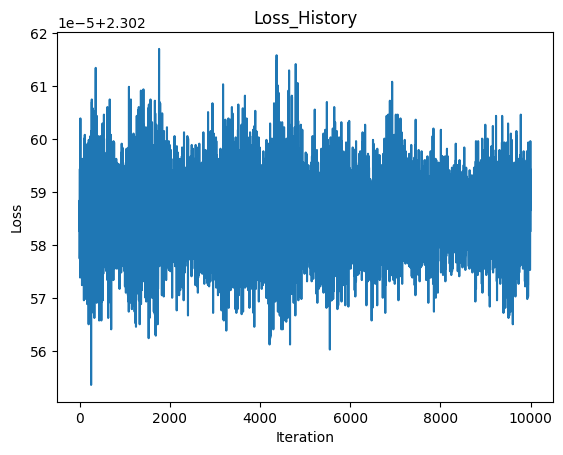

In [10]:
#Plotting Loss history
plt.plot(loss_history)
plt.title("Loss_History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

In [11]:
# calculate accuracy on Training Set
correct_train=0
total_train=0
with torch.no_grad():
    for data in trainloader:
        inputs,labels=data
        Ntr=inputs.shape[0]
        x_train=inputs.view(Ntr,-1)
        y_train_onehot=nn.functional.one_hot(labels,K).float()

        #Forward pass
        h=torch.sigmoid(x_train.mm(w1)+b1)
        y_train_pred=h.mm(w2)+b2
        predicted_train=torch.argmax(y_train_pred,dim=1)
        total_train+=labels.size(0)
        correct_train+=(predicted_train==labels).sum().item()

train_acc=100*correct_train/total_train
print(f"Training_accuracy: {train_acc:.2f}%")

Training_accuracy: 10.00%


In [12]:
# Calculate accuracy on Test Set
correct_test=0
total_test=0
with torch.no_grad():
    for data in testloader:
        inputs,labels=data
        Nte=inputs.shape[0]
        x_test=inputs.view(Nte,-1)
        y_test_onehot=nn.functional.one_hot(labels,K).float()

        # Forward Pass
        h=torch.sigmoid(x_test.mm(w1)+b1)
        y_test_pred=h.mm(w2)+b2
        predicted_test=torch.argmax(y_test_pred,dim=1)
        total_test+=labels.size(0)
        correct_test+=(predicted_test==labels).sum().item()

test_acc=100*correct_test/total_test
print(f"Test_accuracy: {test_acc:.2f}%")

Test_accuracy: 10.00%


A two-layer neural network was implemented by adding a hidden layer containing 100 neurons with sigmoid activation to the original single-layer network. Cross-entropy loss was used for classification, and the gradients were calculated manually using backpropagation. The network was trained on the CIFAR-10 dataset for 10 epochs.

The resulting training accuracy was 10%, and the test accuracy was 10%. These results indicate the model's performance on the training and unseen test datasets. The difference between the two accuracies can provide an indication of how well the network generalizes to unseen images.

Question 02 LeNet-5 network for MNIST using Pytorch

In [13]:
# Transform images into tensor and normalize
transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.1307,),(0.3081,))])
# Load MNIST dataset
train_dataset=torchvision.datasets.MNIST(root="./data",train=True,download=True,transform=transform)
test_dataset=torchvision.datasets.MNIST(root="./data",train=False,download=True,transform=transform)

# create data loaders
train_loader=DataLoader(train_dataset,batch_size=64,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=64,shuffle=False)

#Select CPU or GPU
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:",device)

100%|██████████| 9.91M/9.91M [00:00<00:00, 86.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 3.10MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 27.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.87MB/s]

Using device: cpu


In [14]:
# Define the LeNet-5 model
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5,self).__init__()
        self.features=nn.Sequential(
            #Convolutional layer 1
            nn.Conv2d(1,6,kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2,stride=2),

            #Convolution layer 2
            nn.Conv2d(6,16,kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2,stride=2)
        )
        self.classifier=nn.Sequential(
            nn.Linear(16*4*4,120),
            nn.Tanh(),
            nn.Linear(120,84),
            nn.Tanh(),
            nn.Linear(84,10)
        )

    def forward(self,x):
      x=self.features(x)
      x=torch.flatten(x,1)
      x=self.classifier(x)
      return x
model=LeNet5().to(device)
criterion=nn.CrossEntropyLoss()
optimizer=optim.SGD(model.parameters(),lr=0.01,momentum=0.9)
print(model)

LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Linear(in_features=256, out_features=120, bias=True)
    (1): Tanh()
    (2): Linear(in_features=120, out_features=84, bias=True)
    (3): Tanh()
    (4): Linear(in_features=84, out_features=10, bias=True)
  )
)


In [15]:
def evaluate(model,loaders):
  model.eval()
  correct=0
  total=0
  total_loss=0.0

  with torch.no_grad():
    for images,labels in loaders:
      images,labels=images.to(device),labels.to(device)
      outputs=model(images)
      loss=criterion(outputs,labels)
      total_loss+=loss.item()*labels.size(0)
      _,predicted=torch.max(outputs.data,1)
      total+=labels.size(0)
      correct+=(predicted==labels).sum().item()

  accuracy=100*correct/total
  avg_loss=total_loss/total
  return avg_loss,accuracy

epochs=10
for epoch in range(epochs):
  model.train()
  running_loss=0.0
  correct=0
  total=0
  for images,labels in train_loader:
    images,labels=images.to(device),labels.to(device)
    #forward pass
    outputs=model(images)
    loss=criterion(outputs,labels)

    #backpropagation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    running_loss+=loss.item()*labels.size(0)
    _,predicted=torch.max(outputs,1)

    total+=labels.size(0)
    correct+=(predicted==labels).sum().item()

  train_loss=running_loss/total
  train_accuracy=100*correct/total
  test_loss,test_accuracy=evaluate(model,test_loader)

  print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

Epoch 1/10, Train Loss: 0.3942, Train Accuracy: 89.15%, Test Loss: 0.1093, Test Accuracy: 96.71%
Epoch 2/10, Train Loss: 0.0870, Train Accuracy: 97.50%, Test Loss: 0.0569, Test Accuracy: 98.25%
Epoch 3/10, Train Loss: 0.0605, Train Accuracy: 98.14%, Test Loss: 0.0513, Test Accuracy: 98.27%
Epoch 4/10, Train Loss: 0.0480, Train Accuracy: 98.53%, Test Loss: 0.0429, Test Accuracy: 98.63%
Epoch 5/10, Train Loss: 0.0407, Train Accuracy: 98.75%, Test Loss: 0.0399, Test Accuracy: 98.74%
Epoch 6/10, Train Loss: 0.0363, Train Accuracy: 98.89%, Test Loss: 0.0380, Test Accuracy: 98.80%
Epoch 7/10, Train Loss: 0.0315, Train Accuracy: 99.03%, Test Loss: 0.0394, Test Accuracy: 98.67%
Epoch 8/10, Train Loss: 0.0286, Train Accuracy: 99.10%, Test Loss: 0.0314, Test Accuracy: 98.92%
Epoch 9/10, Train Loss: 0.0247, Train Accuracy: 99.27%, Test Loss: 0.0305, Test Accuracy: 99.01%
Epoch 10/10, Train Loss: 0.0230, Train Accuracy: 99.28%, Test Loss: 0.0285, Test Accuracy: 99.00%


In [16]:
train_loss, train_accuracy = evaluate(model, train_loader)
test_loss, test_accuracy = evaluate(model, test_loader)

print("\nFinal Results After 10 Epochs")
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%")
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")


Final Results After 10 Epochs
Train Loss: 0.0190, Train Accuracy: 99.43%
Test Loss: 0.0285, Test Accuracy: 99.00%


Part b - mplementing a Modern Small CNN

In [17]:
class ModernSmallCNN(nn.Module):
    def __init__(self):
        super(ModernSmallCNN, self).__init__()
        self.features = nn.Sequential(
            #Convolution layer 1
            nn.Conv2d(1,32,kernel_size=3,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

            #Convolution layer 2
            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

            #convolution layer 3
            nn.Conv2d(64,128,kernel_size=3,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Dropout2d(0.25)
        )
        self.classifier=nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*7*7,128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128,10)
        )

    def forward(self,x):
        x=self.features(x)
        x=self.classifier(x)
        return x
model_cnn=ModernSmallCNN().to(device)
criterion_cnn=nn.CrossEntropyLoss()
optimizer_cnn=optim.SGD(model_cnn.parameters(),lr=0.01,momentum=0.9)
print(model_cnn)


ModernSmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout2d(p=0.25, inplace=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Line

In [18]:
epochs=10
for epoch in range(epochs):
  model_cnn.train()
  running_loss=0.0
  correct=0
  total=0
  for images,labels in train_loader:
    images,labels=images.to(device),labels.to(device)
    #forward pass
    outputs=model_cnn(images)
    loss=criterion_cnn(outputs,labels)

    #backpropagation
    optimizer_cnn.zero_grad()
    loss.backward()
    optimizer_cnn.step()
    running_loss+=loss.item()*labels.size(0)
    _,predicted=torch.max(outputs,1)

    total+=labels.size(0)
    correct+=(predicted==labels).sum().item()

  train_loss=running_loss/total
  train_accuracy=100*correct/total
  test_loss,test_accuracy=evaluate(model_cnn,test_loader)

  print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

Epoch 1/10, Train Loss: 0.1676, Train Accuracy: 94.87%, Test Loss: 0.0413, Test Accuracy: 98.61%
Epoch 2/10, Train Loss: 0.0709, Train Accuracy: 97.88%, Test Loss: 0.0266, Test Accuracy: 99.16%
Epoch 3/10, Train Loss: 0.0542, Train Accuracy: 98.40%, Test Loss: 0.0299, Test Accuracy: 99.04%
Epoch 4/10, Train Loss: 0.0452, Train Accuracy: 98.67%, Test Loss: 0.0289, Test Accuracy: 99.00%
Epoch 5/10, Train Loss: 0.0389, Train Accuracy: 98.84%, Test Loss: 0.0199, Test Accuracy: 99.38%
Epoch 6/10, Train Loss: 0.0331, Train Accuracy: 98.93%, Test Loss: 0.0273, Test Accuracy: 99.30%
Epoch 7/10, Train Loss: 0.0297, Train Accuracy: 99.09%, Test Loss: 0.0215, Test Accuracy: 99.30%
Epoch 8/10, Train Loss: 0.0265, Train Accuracy: 99.19%, Test Loss: 0.0179, Test Accuracy: 99.44%
Epoch 9/10, Train Loss: 0.0227, Train Accuracy: 99.30%, Test Loss: 0.0174, Test Accuracy: 99.41%
Epoch 10/10, Train Loss: 0.0192, Train Accuracy: 99.34%, Test Loss: 0.0219, Test Accuracy: 99.36%


Part c - Comparison

In [19]:
lenet_his={
    'train_loss':[],
    'train_acc':[],
    'test_loss':[],
    'test_acc':[]
}
cnn_his={
    'train_loss':[],
    'train_acc':[],
    'test_loss':[],
    'test_acc':[]
}

In [20]:
def train_and_log(model,optimizer,criterion,history,epochs=10):
  for epoch in range(epochs):
    model.train()
    running_loss=0.0
    correct=0
    total=0

    for images,labels in train_loader:
      images,labels=images.to(device),labels.to(device)
      outputs=model(images)
      loss=criterion(outputs,labels)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      running_loss+=loss.item()*labels.size(0)
      _,predicted=torch.max(outputs,1)
      total+=labels.size(0)
      correct+=(predicted==labels).sum().item()

    train_loss=running_loss/total
    train_accuracy=100*correct/total
    test_loss,test_accuracy=evaluate(model,test_loader)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_accuracy)
    history['test_loss'].append(test_loss)
    history['test_acc'].append(test_accuracy)
    print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

In [22]:
train_and_log(model, optimizer, criterion, lenet_his, epochs=10)

train_and_log(model_cnn, optimizer_cnn, criterion_cnn,cnn_his, epochs=10)

Epoch 1/10, Train Loss: 0.0206, Train Accuracy: 99.36%, Test Loss: 0.0279, Test Accuracy: 99.08%
Epoch 2/10, Train Loss: 0.0197, Train Accuracy: 99.42%, Test Loss: 0.0256, Test Accuracy: 99.13%
Epoch 3/10, Train Loss: 0.0175, Train Accuracy: 99.48%, Test Loss: 0.0302, Test Accuracy: 99.03%
Epoch 4/10, Train Loss: 0.0161, Train Accuracy: 99.51%, Test Loss: 0.0264, Test Accuracy: 99.07%
Epoch 5/10, Train Loss: 0.0153, Train Accuracy: 99.53%, Test Loss: 0.0271, Test Accuracy: 99.08%
Epoch 6/10, Train Loss: 0.0130, Train Accuracy: 99.63%, Test Loss: 0.0295, Test Accuracy: 99.02%
Epoch 7/10, Train Loss: 0.0117, Train Accuracy: 99.67%, Test Loss: 0.0288, Test Accuracy: 99.15%
Epoch 8/10, Train Loss: 0.0109, Train Accuracy: 99.72%, Test Loss: 0.0326, Test Accuracy: 98.93%
Epoch 9/10, Train Loss: 0.0103, Train Accuracy: 99.72%, Test Loss: 0.0285, Test Accuracy: 98.98%
Epoch 10/10, Train Loss: 0.0095, Train Accuracy: 99.75%, Test Loss: 0.0279, Test Accuracy: 99.06%
Epoch 1/10, Train Loss: 0.019

In [30]:
import matplotlib.pyplot as plt

def plot_history(history, model_name):

    epoch_numbers = range(1, len(history['train_loss']) + 1)

    # Plot training and test loss
    plt.figure(figsize=(8, 5))
    plt.plot(epoch_numbers, history['train_loss'],
             marker='o', label='Training Loss')
    plt.plot(epoch_numbers, history['test_loss'],
             marker='s', label='Test Loss')

    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'{model_name}: Training and Test Loss')
    plt.xticks(list(epoch_numbers))
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot training and test accuracy
    plt.figure(figsize=(8, 5))
    plt.plot(epoch_numbers, history['train_acc'],
             marker='o', label='Training Acc')
    plt.plot(epoch_numbers, history['test_acc'],
             marker='s', label='Test Acc')

    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title(f'{model_name}: Training and Test Accuracy')
    plt.xticks(list(epoch_numbers))
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

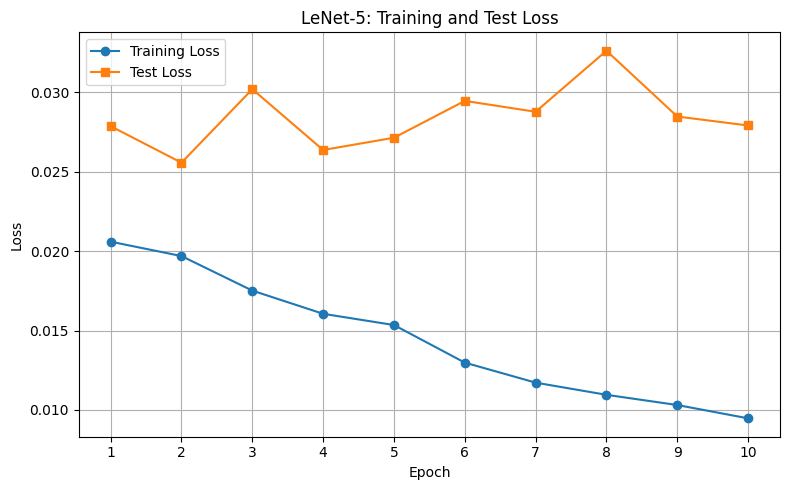

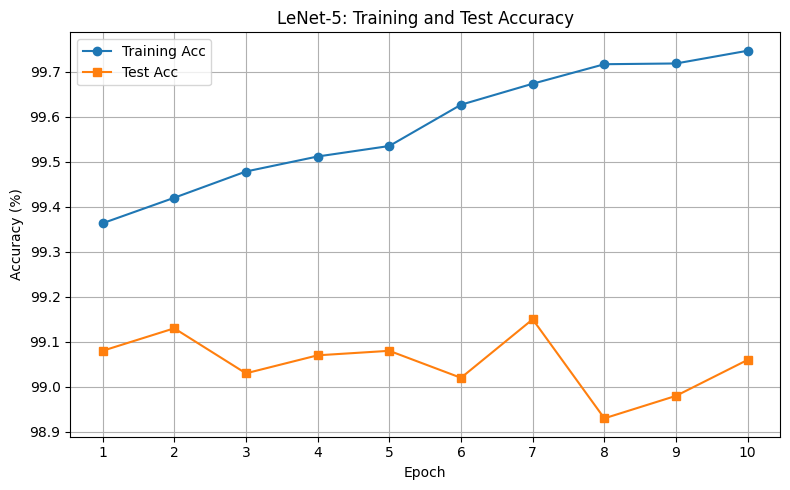

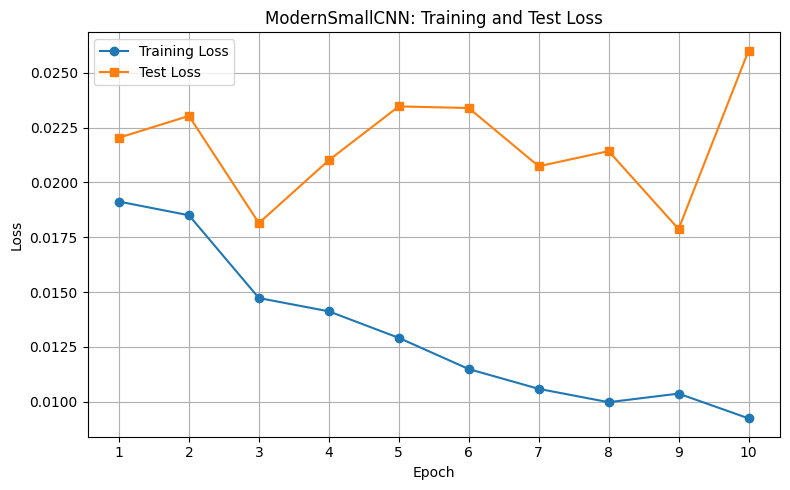

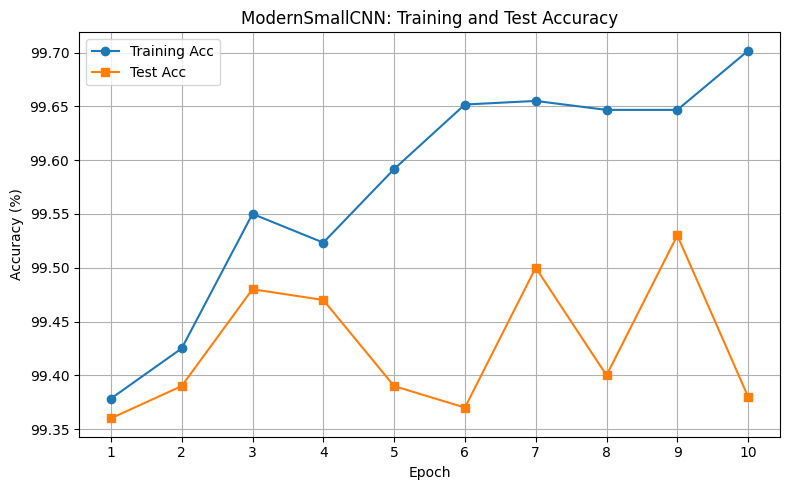

In [31]:
plot_history(lenet_his, 'LeNet-5')
plot_history(cnn_his, 'ModernSmallCNN')

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def show_confusion_matrix(model, model_name):

    model.eval()
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            all_labels.extend(labels.numpy())
            all_predictions.extend(predicted.cpu().numpy())

    cm = confusion_matrix(
        all_labels,
        all_predictions,
        labels=list(range(10))
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=list(range(10))
    )

    fig, ax = plt.subplots(figsize=(8, 8))
    display.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(f'{model_name} Confusion Matrix')
    plt.tight_layout()
    plt.show()

    return cm

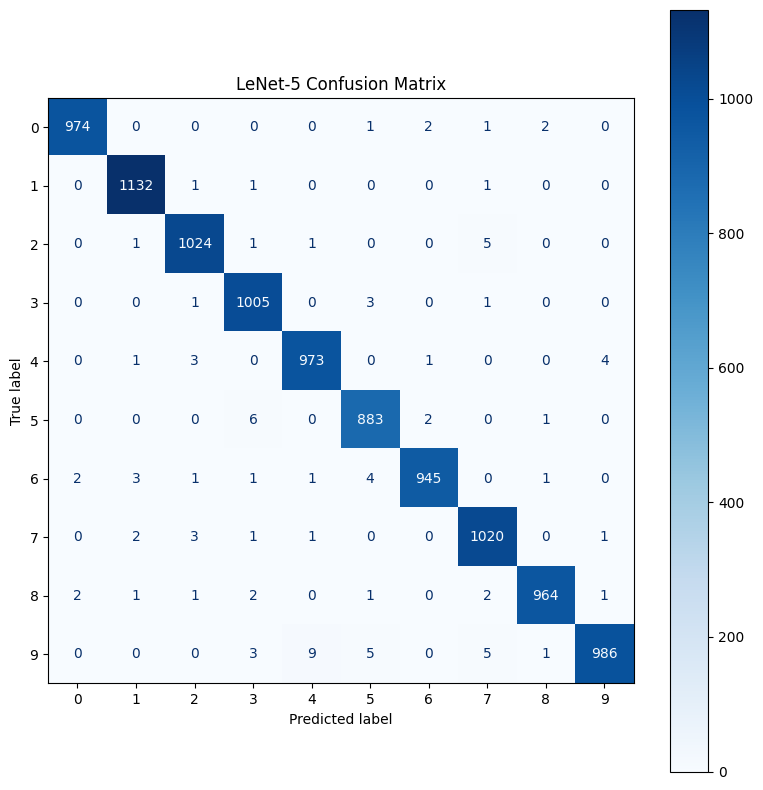

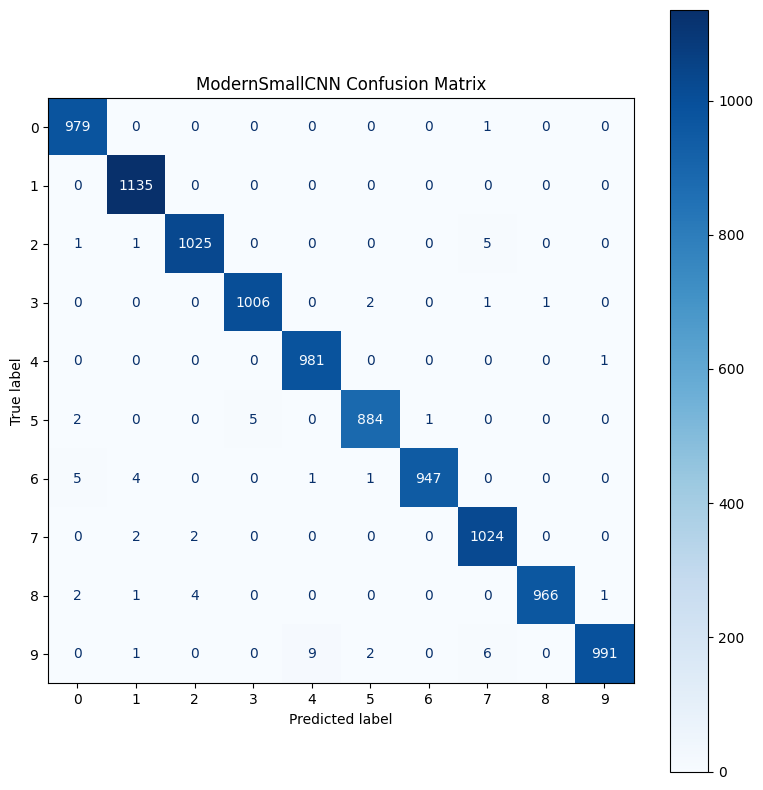

In [33]:
lenet_cm = show_confusion_matrix(model, 'LeNet-5')

cnn_cm = show_confusion_matrix(model_cnn, 'ModernSmallCNN')

Both LeNet-5 and ModernSmallCNN were trained on the MNIST dataset for 10 epochs. The training and test loss and accuracy were recorded for each epoch to compare their learning performance.
LeNet-5 uses two convolutional layers with Tanh activation and average pooling, whereas ModernSmallCNN uses three convolutional layers with ReLU activation, batch normalization, max pooling, and dropout. The additional convolutional layer allows ModernSmallCNN to extract more complex features, while batch normalization and dropout help stabilize training and reduce overfitting.
The loss and accuracy curves were used to evaluate the learning progress and generalization ability of both models. The confusion matrices showed the number of correct and incorrect predictions for each digit from 0 to 9. Misclassifications indicate that some handwritten digits have similar visual features.
Overall, the better-performing model can be identified by comparing the final test accuracy, test loss, and confusion matrices. The results also help determine which model provides better classification performance on unseen MNIST test images.

Question 3 -

In [34]:
!wget -q https://download.pytorch.org/tutorial/hymenoptera_data.zip
!unzip -qo hymenoptera_data.zip

In [41]:
from torchvision import datasets, models, transforms
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import time
import copy
import os

In [43]:
data_dir = "hymenoptera_data"

data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}

image_datasets = {phase: datasets.ImageFolder(
        os.path.join(data_dir, phase),
        transform=data_transforms[phase]
    )
    for phase in ["train", "val"]
}

dataloaders = {
    phase: DataLoader(
        image_datasets[phase],
        batch_size=4,
        shuffle=(phase == "train"),
        num_workers=2
    )
    for phase in ["train", "val"]
}

dataset_sizes = {
    phase: len(image_datasets[phase])
    for phase in ["train", "val"]
}

class_names = image_datasets["train"].classes

print("Classes:", class_names)
print("Dataset sizes:", dataset_sizes)

Classes: ['ants', 'bees']
Dataset sizes: {'train': 244, 'val': 153}


In [44]:
# Training
def train_model(model, criterion, optimizer, scheduler, epochs=10):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):
        print(f"\nEpoch {epoch + 1}/{epochs}")
        print("-" * 30)

        for phase in ["train", "val"]:
            if phase == "train":
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    _, preds = torch.max(outputs, 1)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(
                    preds == labels
                ).item()

            epoch_loss = (
                running_loss / dataset_sizes[phase]
            )
            epoch_acc = (
                running_corrects / dataset_sizes[phase]
            )

            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)

            print(
                f"{phase} Loss: {epoch_loss:.4f} "
                f"Acc: {epoch_acc:.4f}"
            )

            if phase == "val" and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(
                    model.state_dict()
                )

        if scheduler is not None:
            scheduler.step()

    elapsed = time.time() - since
    print(f"\nTraining time: {elapsed:.1f} seconds")
    print(f"Best validation accuracy: {best_acc:.4f}")

    model.load_state_dict(best_model_wts)

    return model, history

Part a - Fine Tunning ResNet18

In [45]:
model_ft = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

num_ftrs = model_ft.fc.in_features

model_ft.fc = nn.Linear(num_ftrs, 2)
model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

optimizer_ft = optim.SGD(
    model_ft.parameters(),
    lr=0.001,
    momentum=0.9
)

scheduler_ft = lr_scheduler.StepLR(
    optimizer_ft,
    step_size=7,
    gamma=0.1
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 254MB/s]


In [46]:
# Train Fine tunned model
model_ft, history_ft = train_model(
    model_ft,
    criterion,
    optimizer_ft,
    scheduler_ft,
    epochs=10
)


Epoch 1/10
------------------------------
train Loss: 0.6699 Acc: 0.6803
val Loss: 0.2277 Acc: 0.9216

Epoch 2/10
------------------------------
train Loss: 0.5638 Acc: 0.7705
val Loss: 0.5333 Acc: 0.7843

Epoch 3/10
------------------------------
train Loss: 0.4795 Acc: 0.8033
val Loss: 0.2677 Acc: 0.8889

Epoch 4/10
------------------------------
train Loss: 0.5677 Acc: 0.7910
val Loss: 0.3470 Acc: 0.8824

Epoch 5/10
------------------------------
train Loss: 0.4383 Acc: 0.8033
val Loss: 0.2217 Acc: 0.9020

Epoch 6/10
------------------------------
train Loss: 0.4528 Acc: 0.8320
val Loss: 0.2828 Acc: 0.9216

Epoch 7/10
------------------------------
train Loss: 0.2904 Acc: 0.8689
val Loss: 0.3941 Acc: 0.8824

Epoch 8/10
------------------------------
train Loss: 0.3543 Acc: 0.8525
val Loss: 0.2999 Acc: 0.9085

Epoch 9/10
------------------------------
train Loss: 0.3696 Acc: 0.8525
val Loss: 0.2620 Acc: 0.9085

Epoch 10/10
------------------------------
train Loss: 0.2672 Acc: 0.881

Part b - ResNet18 as a fixed feature extractor

In [47]:
model_fe = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

# Freeze all pretrained parameters
for param in model_fe.parameters():
    param.requires_grad = False

# Replace the classifier
num_ftrs = model_fe.fc.in_features
model_fe.fc = nn.Linear(num_ftrs, 2)

model_fe = model_fe.to(device)

criterion = nn.CrossEntropyLoss()

# Optimize only the newly initialized classifier
optimizer_fe = optim.SGD(
    model_fe.fc.parameters(),
    lr=0.001,
    momentum=0.9
)

scheduler_fe = lr_scheduler.StepLR(
    optimizer_fe,
    step_size=7,
    gamma=0.1
)

print("Trainable parameters:")
print(sum(
    p.numel() for p in model_fe.parameters()
    if p.requires_grad
))

Trainable parameters:
1026


In [48]:
#Training
model_fe, history_fe = train_model(
    model_fe,
    criterion,
    optimizer_fe,
    scheduler_fe,
    epochs=10
)


Epoch 1/10
------------------------------
train Loss: 0.7629 Acc: 0.6680
val Loss: 0.2933 Acc: 0.9020

Epoch 2/10
------------------------------
train Loss: 0.5386 Acc: 0.7705
val Loss: 0.1826 Acc: 0.9477

Epoch 3/10
------------------------------
train Loss: 0.4948 Acc: 0.7705
val Loss: 0.2437 Acc: 0.9020

Epoch 4/10
------------------------------
train Loss: 0.5174 Acc: 0.7705
val Loss: 0.1738 Acc: 0.9477

Epoch 5/10
------------------------------
train Loss: 0.4273 Acc: 0.8197
val Loss: 0.1997 Acc: 0.9412

Epoch 6/10
------------------------------
train Loss: 0.4207 Acc: 0.8238
val Loss: 0.3734 Acc: 0.8562

Epoch 7/10
------------------------------
train Loss: 0.4514 Acc: 0.7910
val Loss: 0.1681 Acc: 0.9477

Epoch 8/10
------------------------------
train Loss: 0.4009 Acc: 0.8197
val Loss: 0.1846 Acc: 0.9412

Epoch 9/10
------------------------------
train Loss: 0.3310 Acc: 0.8607
val Loss: 0.1902 Acc: 0.9346

Epoch 10/10
------------------------------
train Loss: 0.3580 Acc: 0.823

Plot training and validation results

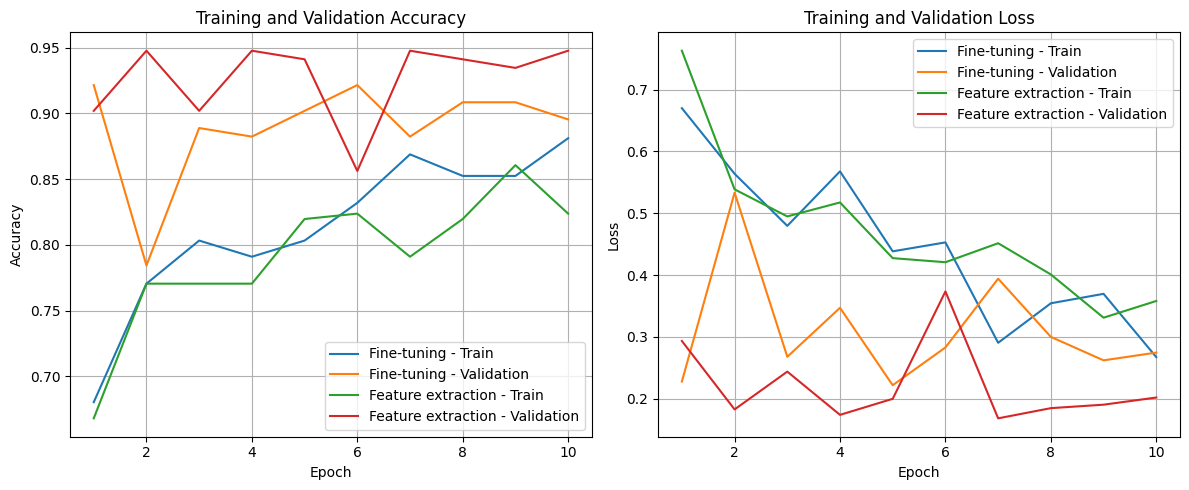

In [49]:
def plot_history(history_ft, history_fe):
    epochs = range(1, len(history_ft["train_acc"]) + 1)

    plt.figure(figsize=(12, 5))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history_ft["train_acc"],
             label="Fine-tuning - Train")
    plt.plot(epochs, history_ft["val_acc"],
             label="Fine-tuning - Validation")
    plt.plot(epochs, history_fe["train_acc"],
             label="Feature extraction - Train")
    plt.plot(epochs, history_fe["val_acc"],
             label="Feature extraction - Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Training and Validation Accuracy")
    plt.legend()
    plt.grid(True)

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history_ft["train_loss"],
             label="Fine-tuning - Train")
    plt.plot(epochs, history_ft["val_loss"],
             label="Fine-tuning - Validation")
    plt.plot(epochs, history_fe["train_loss"],
             label="Feature extraction - Train")
    plt.plot(epochs, history_fe["val_loss"],
             label="Feature extraction - Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_history(history_ft, history_fe)


Fine-tuning
Validation accuracy: 0.9216
Validation accuracy: 92.16%

Classification report:
              precision    recall  f1-score   support

        ants       0.90      0.93      0.92        70
        bees       0.94      0.92      0.93        83

    accuracy                           0.92       153
   macro avg       0.92      0.92      0.92       153
weighted avg       0.92      0.92      0.92       153



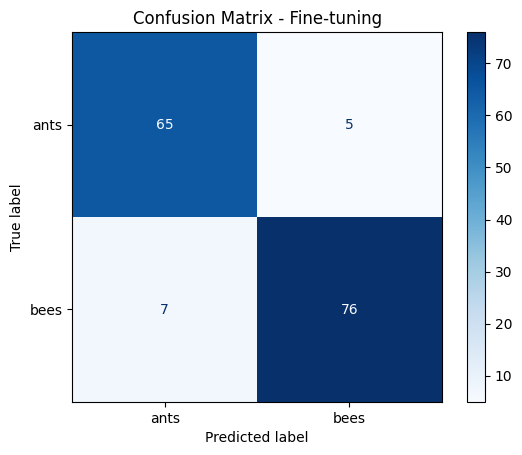


Feature extraction
Validation accuracy: 0.9477
Validation accuracy: 94.77%

Classification report:
              precision    recall  f1-score   support

        ants       0.92      0.97      0.94        70
        bees       0.97      0.93      0.95        83

    accuracy                           0.95       153
   macro avg       0.95      0.95      0.95       153
weighted avg       0.95      0.95      0.95       153



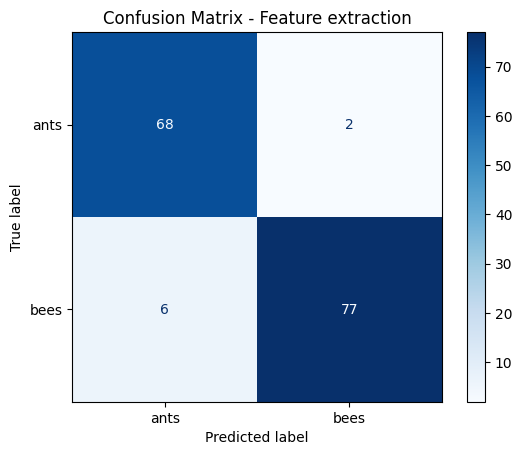

In [50]:
#Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

def evaluate_model(model, model_name):
    model.eval()

    all_labels = []
    all_preds = []

    with torch.no_grad():
        for inputs, labels in dataloaders["val"]:
            inputs = inputs.to(device)

            outputs = model(inputs)
            preds = outputs.argmax(dim=1).cpu()

            all_labels.extend(labels.numpy())
            all_preds.extend(preds.numpy())

    accuracy = accuracy_score(all_labels, all_preds)

    print(f"\n{model_name}")
    print(f"Validation accuracy: {accuracy:.4f}")
    print(f"Validation accuracy: {accuracy * 100:.2f}%")

    print("\nClassification report:")
    print(classification_report(
        all_labels,
        all_preds,
        labels=[0, 1],
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(
        all_labels, all_preds, labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    ).plot(cmap="Blues", values_format="d")

    plt.title(f"Confusion Matrix - {model_name}")
    plt.show()

    return accuracy, cm


acc_ft, cm_ft = evaluate_model(
    model_ft, "Fine-tuning"
)

acc_fe, cm_fe = evaluate_model(
    model_fe, "Feature extraction"
)

In [51]:
#results
import pandas as pd

results = pd.DataFrame({
    "Method": [
        "Fine-tuning",
        "Feature extraction"
    ],
    "Best Validation Accuracy (%)": [
        max(history_ft["val_acc"]) * 100,
        max(history_fe["val_acc"]) * 100
    ],
    "Final Training Accuracy (%)": [
        history_ft["train_acc"][-1] * 100,
        history_fe["train_acc"][-1] * 100
    ],
    "Final Training Loss": [
        history_ft["train_loss"][-1],
        history_fe["train_loss"][-1]
    ],
    "Final Validation Loss": [
        history_ft["val_loss"][-1],
        history_fe["val_loss"][-1]
    ]
})

print(results.round(4).to_string(index=False))

            Method  Best Validation Accuracy (%)  Final Training Accuracy (%)  Final Training Loss  Final Validation Loss
       Fine-tuning                       92.1569                      88.1148               0.2672                 0.2745
Feature extraction                       94.7712                      82.3770               0.3580                 0.2018
